In [ ]:
%load_ext autoreload
%autoreload 2
# %matplotlib inline

import os

# to allow deterministic gradients on CUDA
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

while 'notebooks' in os.getcwd():
    os.chdir("../")

# !pwd

import torch
from torch import nn, einsum

# determnistic = True
determnistic = False  # doesn't always work with some layers
torch.use_deterministic_algorithms(determnistic)
torch.backends.cudnn.deterministic = determnistic

import quantus
import gc
import torch.nn.functional as F

from lib.helpers import plot_example_grid, make_2x2_batch_from_classes, batched_cmap_rgb, \
    squeeze_channels, normalise_by_negative_batch, show_images
from lib.attributions import GradientAscentDiff, PullbackAscentDiff, \
    quantus_pullback_ascent_diff_explain_func
from lib.setup import setup_notebook
from lib.defaults import get_default_kwargs
from lib.surrogates import LayerNorm2d, PVTAttention, soften_module_inplace_
from lib.evaluator import QuantusEvaluator, default_explainers, default_metrics
from lib.dataset import CLASS_NAMES, get_examples


batch_size = 50
# model_name = "resnet50"
model_name = "vgg11_bn"
model_source = "torchvision"

# model_name = "pvt_v2_b1"
# model_source = "timm"
# dataset = "imagenet"
dataset = "imagenette"

seed = 314

device, loader, model = setup_notebook(batch_size=batch_size, model_name=model_name, model_source=model_source, seed=seed, dataset=dataset)

# it = iter(loader)
# images, labels = next(it)

# x_batch = images.numpy()
# y_batch = labels.numpy()
# images = images.to(device)
# labels = labels.to(device)

n_show = min(15, batch_size)

# # print(len(loader.dataset))
# print(images.min(), images.max(), images.mean(), images.std())
# print(f"images.shape = {images.shape}")
# print(f"labels = {labels[:n_show].tolist()}")

# plot_example_grid(images[:n_show], nrow=min(5, n_show))

In [2]:
# img, tgt = get_examples(loader)#, classes=[0, 2, 4, 6, 8, 9])
img, tgt = get_examples(loader)
# img, tgt = images[10:15], labels[10:15]
# img, tgt = images, labels

In [3]:
temperatures, pga_kwargs_counterfactual, pga_kwargs_grad, pga_kwargs_adv = get_default_kwargs()

alpha = 20
K = 10

pga_kwargs_counterfactual = {**pga_kwargs_counterfactual, "alpha": alpha, "steps": K}

# modify the model in-place, but don't change its backward behavior
soften_module_inplace_(model, temperatures=temperatures, standard_backward=True, fill_default_temperatures=True)

explainers = default_explainers(["PullbackAscent", "GradientAscent"], pga_kwargs_counterfactual=pga_kwargs_counterfactual)

metrics = default_metrics(["sparseness"])

In [4]:
explainers

{'PullbackAscent': (<function lib.attributions.quantus_pullback_ascent_diff_explain_func(model, inputs, targets, temperatures=None, squeeze_channel_mode=None, device=None, **pga_kwargs)>,
  {'alpha': 20,
   'steps': 10,
   'eps': None,
   'normalize_step': True,
   'relative_alpha': False,
   'clip_margin': None}),
 'GradientAscent': (<function lib.attributions.quantus_gradient_ascent_diff_explain_func(model, inputs, targets, squeeze_channel_mode=None, device=None, **pga_kwargs)>,
  {'alpha': 20,
   'steps': 10,
   'eps': None,
   'normalize_step': True,
   'relative_alpha': False,
   'clip_margin': None})}

In [5]:
evaluator = QuantusEvaluator(
    model,
    metrics,
    explainers,
    device=device,
)

In [6]:
img, tgt = img.to(device), tgt.to(device)

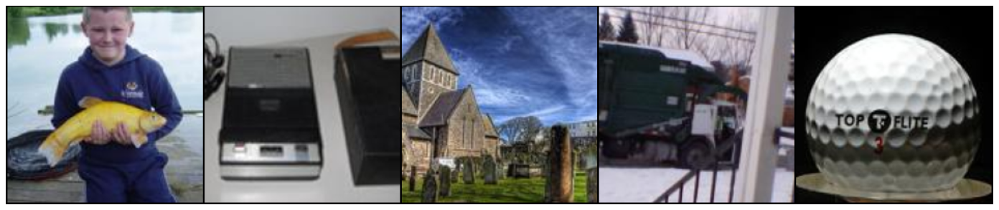

In [7]:
plot_example_grid(img, nrow=min(5, len(img)))

In [8]:
imgg = img.repeat_interleave(5, dim=0)#.shape#img.shape
tgtt = tgt.repeat(5)#.shape#tgt.shape
tgtt

tensor([  0, 482, 497, 569, 574,   0, 482, 497, 569, 574,   0, 482, 497, 569,
        574,   0, 482, 497, 569, 574,   0, 482, 497, 569, 574],
       device='cuda:0')

In [9]:
evaluator.precompute_attributions(imgg, tgtt)
attrs = {name: torch.as_tensor(attr) for name, attr in evaluator.attributions.items()}

Precomputing attributions for explainer PullbackAscent
Explainer PullbackAscent took 3.854 seconds.
Precomputing attributions for explainer GradientAscent
Explainer GradientAscent took 1.548 seconds.


In [10]:
attrs.keys()

dict_keys(['PullbackAscent', 'GradientAscent'])

In [11]:
attr_name = 'PullbackAscent'
# attr_name = 'GradientAscent'

xx = attrs[attr_name].to(device)
xx.shape

torch.Size([25, 3, 224, 224])

In [12]:
# make counterfactuals by adding the attribution to the image, but clip to valid range and remove the attribution again
# (so that only the "excess" part of the attribution remains)
xx = (xx + imgg).clip(-1, 1) - imgg

In [13]:
# attr_name
xx.min(), xx.max(), xx.mean(), xx.std()

(tensor(-2., device='cuda:0'),
 tensor(1.9843, device='cuda:0'),
 tensor(0.0110, device='cuda:0'),
 tensor(0.2292, device='cuda:0'))

In [14]:
xx.shape, imgg.shape

(torch.Size([25, 3, 224, 224]), torch.Size([25, 3, 224, 224]))

In [15]:
# xx = (imgg + xx).clip(-1, 1)
# xx = xx - imgg

In [16]:
from lib.helpers import as_cmap_rgb
mode = "mean"
# mode = "norm"
# mode = "abs_mean"
cmap = "seismic"
# cmap = "gray"
# cmap = "inferno"
# normalise = False
normalise = True

def apply_cmap(batch):
    return as_cmap_rgb(batch, cmap_name=cmap, mode=mode, normalise=normalise)

xx_cmap = apply_cmap(xx).to(imgg.device)

In [17]:
show, show_diff = show_images(img, imgg + xx, k=5)
# show, show_diff = show_images(img, imgg + xx_cmap, k=5)
show.shape

torch.Size([30, 3, 224, 224])

In [18]:
with open("imagenet1000_clsidx_to_labels.txt", "r", encoding="utf-8") as f:
    content = f.read()
imagenet_labels = eval(content)

In [19]:
from lib.dataset import CLASS_NAMES
column_titles = ["Image"] + [CLASS_NAMES[c.item()][0] for c in tgt]
# column_titles_full = ["Image"] + [imagenet_labels[c.item()] for c in tgt]
# column_titles = [t[:10] for t in column_titles_full]
# column_titles_full

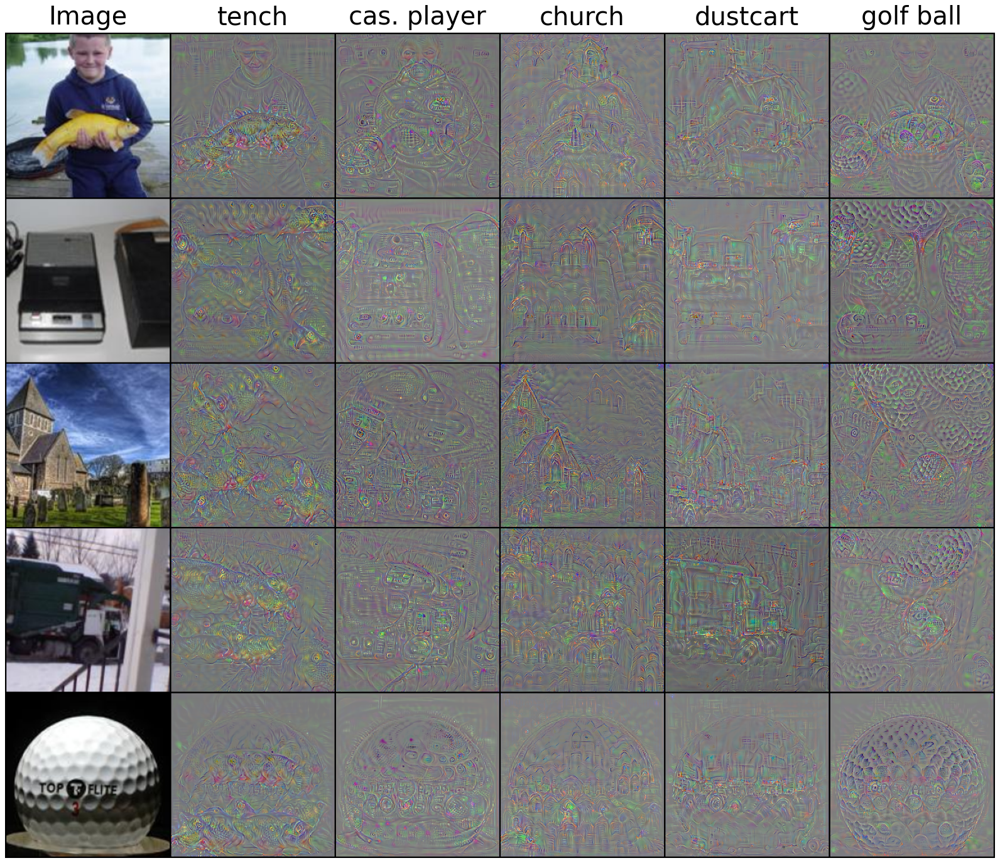

In [ ]:
plot_example_grid(show_diff, nrow=6, heatmap=False, dpi=80, cmap="seismic", column_titles=column_titles, fontsize=36, save_path=f"media/counterfactuals/K_{K}/counterfactuals_diff_{model_name}_{attr_name}_alpha_{alpha}_K_{K}.jpg")

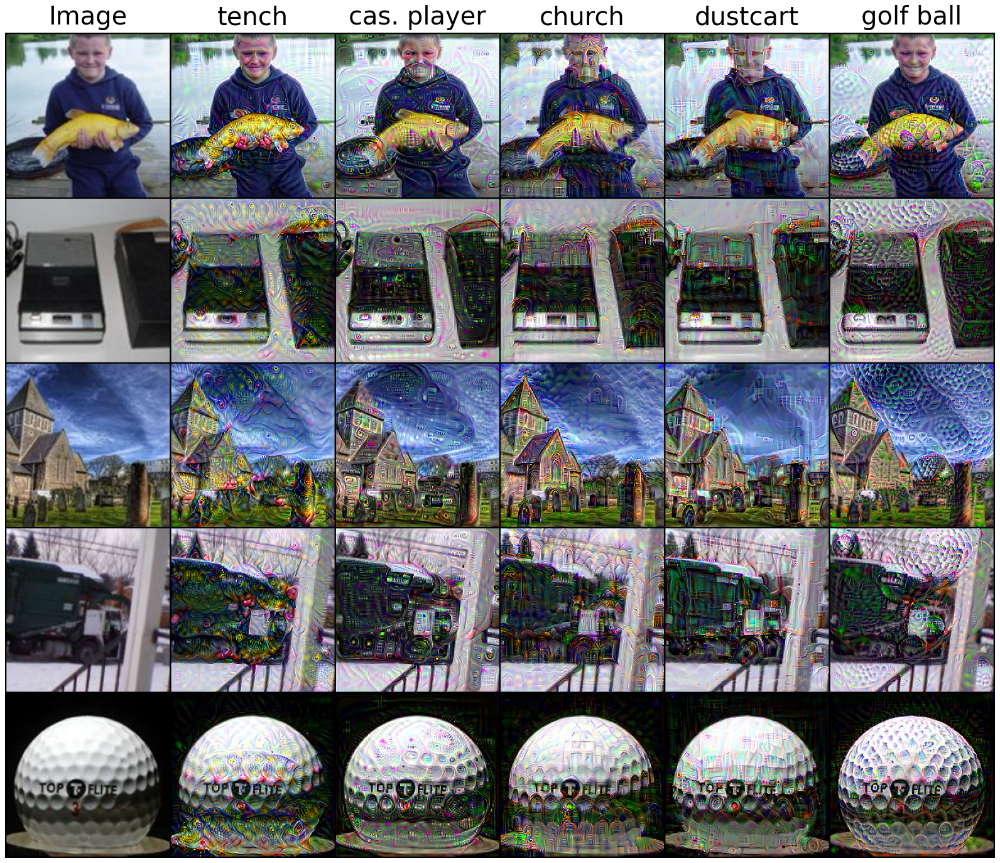

In [95]:
plot_example_grid(show, nrow=6, heatmap=False, dpi=80, cmap="seismic", column_titles=column_titles, fontsize=36, save_path=f"media/counterfactuals/K_{K}/counterfactuals_{model_name}_{attr_name}_alpha_{alpha}_K_{K}.jpg")

In [34]:
# plot_example_grid(show_diff, nrow=6, heatmap=True, dpi=80, cmap="seismic", column_titles=column_titles, fontsize=36, save_path=f"media/counterfactuals/K_{K}/counterfactuals_diff_{model_name}_{attr_name}_alpha_{alpha}_K_{K}.jpg")